# Statistik
## 03 - Wahrscheinlichkeitsrechnung

**Voraussetzungen:** Beschreibende Statistik (Häufigkeiten, Mittelwert, Streuung), Grundlagen der Mengenlehre

In der beschreibenden Statistik haben wir *beobachtete* Daten ausgewertet - Häufigkeiten gezählt, Mittelwerte berechnet, Zusammenhänge visualisiert. Dabei taucht immer wieder eine Frage auf: **Wie „typisch" ist das, was wir beobachtet haben?** Ist ein Mittelwert zufällig so hoch ausgefallen, oder steckt etwas Systematisches dahinter?

Um solche Fragen beantworten zu können, brauchen wir ein **mathematisches Modell für den Zufall**. Genau das liefert die Wahrscheinlichkeitsrechnung. Sie gibt uns Werkzeuge an die Hand, mit denen wir Aussagen treffen können wie *„Die Wahrscheinlichkeit, dass…"* - und zwar auf einer soliden, axiomatischen Grundlage.

Dieses Notebook baut die Theorie von Grund auf:
- Wir definieren die **Sprache** (Ergebnisse, Ereignisse, Mengenoperationen).
- Wir lernen **drei Wege**, Wahrscheinlichkeiten zuzuordnen (Laplace, frequentistisch, axiomatisch).
- Wir entwickeln **Rechenregeln**, die aus den Axiomen folgen.
- Wir lernen **Zähltechniken** (Kombinatorik), um Laplace-Wahrscheinlichkeiten berechnen zu können.
- Wir behandeln **bedingte Wahrscheinlichkeiten**, Baumdiagramme und den **Satz von Bayes**.

### Lernziele

- Du kennst die Begriffe **Zufallsexperiment**, **Ergebnis**, **Ergebnismenge** und **Ereignis**.
- Du kannst Ereignisse mit **Mengenoperationen** verknüpfen und in **Venn-Diagrammen** darstellen.
- Du verstehst die **drei Wahrscheinlichkeitsbegriffe** und ihre Beziehung zueinander.
- Du beherrschst die zentralen **Rechenregeln** (Additions-, Komplementärregel).
- Du kannst mit **Kombinatorik** die Anzahl günstiger und möglicher Fälle bestimmen.
- Du verstehst **bedingte Wahrscheinlichkeit**, **Unabhängigkeit** und **Pfadregeln**.
- Du kannst den **Satz von Bayes** anwenden und interpretieren.

---

### 1. Grundbegriffe

#### Zufallsexperiment

Ein **Zufallsexperiment** ist ein Vorgang, der unter festgelegten Bedingungen durchgeführt wird und dessen Ausgang nicht mit Sicherheit vorhergesagt werden kann. Entscheidend sind zwei Eigenschaften:

1. Das Experiment lässt sich (zumindest prinzipiell) **unter gleichen Bedingungen wiederholen**.
2. Der **Ausgang ist nicht eindeutig bestimmbar** - es gibt mehrere mögliche Ergebnisse.

Das Werfen eines Würfels ist das Schulbeispiel: Wir wissen, dass eine der Zahlen 1 bis 6 fallen wird, aber nicht *welche*. Hingegen ist das Berechnen von $2 + 3$ kein Zufallsexperiment - das Ergebnis steht fest.

#### Ergebnis und Ergebnismenge

> **Definition:**
> - Ein **Ergebnis** (auch: Elementarereignis) $\omega$ ist ein einzelner möglicher Ausgang eines Zufallsexperiments.
> - Die **Ergebnismenge** (auch: Grundraum) $\Omega$ ist die Menge *aller* möglichen Ergebnisse.

Jedes Zufallsexperiment hat genau eine Ergebnismenge, und bei jeder Durchführung tritt genau ein $\omega \in \Omega$ ein.

**Beispiele:**

- **Münzwurf:** $\Omega = \{K, Z\}$ - Kopf oder Zahl.
- **Würfelwurf:** $\Omega = \{1, 2, 3, 4, 5, 6\}$ - sechs mögliche Augenzahlen.
- **Zwei Münzwürfe:** $\Omega = \{KK, KZ, ZK, ZZ\}$ - vier mögliche Kombinationen. Beachte, dass $KZ$ und $ZK$ verschiedene Ergebnisse sind (die Reihenfolge zählt).
- **Summe zweier Würfel:** $\Omega = \{2, 3, 4, \ldots, 12\}$ - elf mögliche Summen. Hier ist allerdings Vorsicht geboten: Die Ergebnisse sind **nicht gleichwahrscheinlich** (eine 7 kann auf mehr Arten entstehen als eine 2). Dazu kommen wir bei Laplace.

Die Ergebnismenge kann **endlich** sein (wie oben), **abzählbar unendlich** (z.B. „Wie oft muss man würfeln, bis die erste 6 fällt?" → $\Omega = \{1, 2, 3, \ldots\}$) oder sogar **überabzählbar** (z.B. „Wie lange dauert ein Telefonat?" → $\Omega = [0, \infty)$). In diesem Notebook beschränken wir uns auf **endliche** Ergebnismengen.

---

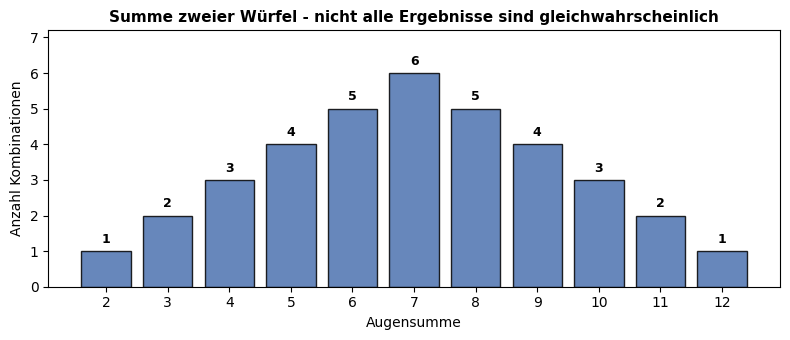

In [1]:
# === KONFIGURATION: Ergebnismengen als Python-Sets ===
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn2, venn3
from itertools import product
import math

random.seed(42)
np.random.seed(42)

# --- Ergebnismengen verschiedener Zufallsexperimente ---
muenzwurf = {"K", "Z"}
wuerfelwurf = {1, 2, 3, 4, 5, 6}
zwei_muenzen = {a + b for a, b in product("KZ", repeat=2)}
zwei_wuerfel = {(i, j) for i in range(1, 7) for j in range(1, 7)}

# --- Visualisierung: Summe zweier Würfel (nicht gleichwahrscheinlich!) ---
summen = [i + j for i in range(1, 7) for j in range(1, 7)]
werte, haeufigkeiten = np.unique(summen, return_counts=True)

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(werte, haeufigkeiten, color="#4C72B0", edgecolor="black", alpha=0.85)
ax.set_xlabel("Augensumme")
ax.set_ylabel("Anzahl Kombinationen")
ax.set_title("Summe zweier Würfel - nicht alle Ergebnisse sind gleichwahrscheinlich", fontsize=11, fontweight="bold")
ax.set_xticks(werte)

for bar, h in zip(bars, haeufigkeiten):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15, str(h),
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylim(0, max(haeufigkeiten) + 1.2)
plt.tight_layout()
plt.show()

### 2. Ereignisse und Mengenoperationen

#### Ereignis

Ein **Ereignis** ist eine Teilmenge der Ergebnismenge: $A \subseteq \Omega$. Ein Ereignis $A$ *tritt ein*, wenn das tatsächliche Ergebnis $\omega$ des Experiments in $A$ liegt, also $\omega \in A$.

> **Definition:**
> - Ein **Elementarereignis** enthält genau ein Ergebnis: $\{\omega\}$.
> - Das **sichere Ereignis** ist $\Omega$ selbst - es tritt *immer* ein, egal was passiert.
> - Das **unmögliche Ereignis** ist die leere Menge $\emptyset$ - es kann *nie* eintreten.

**Beispiel** (Würfelwurf, $\Omega = \{1,2,3,4,5,6\}$):
- $A = \{2, 4, 6\}$: „Es fällt eine gerade Zahl"
- $B = \{5, 6\}$: „Es fällt eine Zahl größer als 4"
- $\{3\}$: Elementarereignis „Es fällt eine 3"

#### Mengenoperationen auf Ereignissen

Da Ereignisse Mengen sind, können wir sie mit den bekannten Mengenoperationen verknüpfen. Jede Operation hat eine anschauliche Bedeutung in der Sprache der Wahrscheinlichkeit:

**Vereinigung** $A \cup B$ - *„A oder B (oder beide)"*: Das Ereignis tritt ein, wenn **mindestens eines** der beiden Ereignisse eintritt. Im Würfelbeispiel: $A \cup B = \{2, 4, 5, 6\}$ - „gerade oder größer als 4".

**Durchschnitt** $A \cap B$ - *„A und B"*: Das Ereignis tritt ein, wenn **beide** gleichzeitig eintreten. Im Beispiel: $A \cap B = \{6\}$ - „gerade und größer als 4", also nur die 6.

**Komplement** $\bar{A} = \Omega \setminus A$ - *„nicht A"*: Das Ereignis tritt ein, wenn $A$ **nicht** eintritt. Im Beispiel: $\bar{A} = \{1, 3, 5\}$ - „ungerade Zahl".

**Differenz** $A \setminus B$ - *„A, aber nicht B"*: $A$ tritt ein, $B$ aber nicht. Im Beispiel: $A \setminus B = \{2, 4\}$ - „gerade, aber nicht größer als 4".

**Disjunkte Ereignisse:** Zwei Ereignisse heißen **disjunkt** (oder unvereinbar), wenn sie nicht gleichzeitig eintreten können: $A \cap B = \emptyset$. Zum Beispiel sind $\{1, 2, 3\}$ und $\{4, 5, 6\}$ disjunkt - wenn eine Zahl $\leq 3$ fällt, kann sie nicht gleichzeitig $\geq 4$ sein.

#### De-Morgansche Regeln

Diese Regeln verknüpfen Komplement mit Vereinigung und Durchschnitt - sie sind nützlich, wenn man Ereignisse „umformulieren" möchte:

$$\overline{A \cup B} = \bar{A} \cap \bar{B} \qquad \text{und} \qquad \overline{A \cap B} = \bar{A} \cup \bar{B}$$

In Worten: *„Weder A noch B"* ist dasselbe wie *„nicht A und nicht B"*. Und *„nicht (A und B gleichzeitig)"* ist dasselbe wie *„nicht A oder nicht B"*.

---

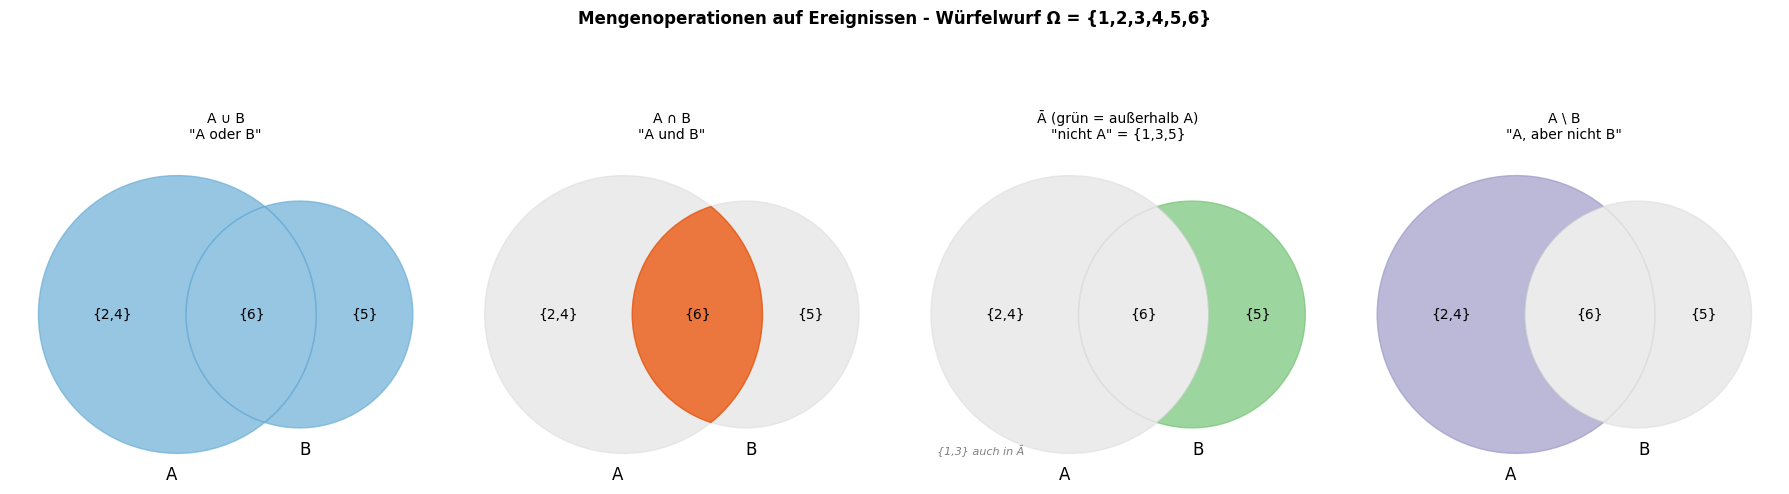

In [5]:
# === Venn-Diagramme: Mengenoperationen auf Ereignissen ===
from matplotlib_venn import venn2

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
fig.suptitle("Mengenoperationen auf Ereignissen - Würfelwurf Ω = {1,2,3,4,5,6}", fontsize=12, fontweight="bold")

# Konfiguration: A = gerade, B = >4
# A = {2,4,6}, B = {5,6}  →  A∩B = {6}, A∪B = {2,4,5,6}, Ā = {1,3,5}

# --- A ∪ B ---
v1 = venn2(subsets=(2, 1, 1), set_labels=("A", "B"), ax=axes[0])
v1.get_patch_by_id("10").set_color("#6BAED6")
v1.get_patch_by_id("01").set_color("#6BAED6")
v1.get_patch_by_id("11").set_color("#6BAED6")
v1.get_patch_by_id("10").set_alpha(0.7)
v1.get_patch_by_id("01").set_alpha(0.7)
v1.get_patch_by_id("11").set_alpha(0.7)
v1.get_label_by_id("10").set_text("{2,4}")
v1.get_label_by_id("01").set_text("{5}")
v1.get_label_by_id("11").set_text("{6}")
axes[0].set_title('A ∪ B\n"A oder B"', fontsize=10)

# --- A ∩ B ---
v2 = venn2(subsets=(2, 1, 1), set_labels=("A", "B"), ax=axes[1])
v2.get_patch_by_id("10").set_color("#D9D9D9")
v2.get_patch_by_id("01").set_color("#D9D9D9")
v2.get_patch_by_id("11").set_color("#E6550D")
v2.get_patch_by_id("10").set_alpha(0.5)
v2.get_patch_by_id("01").set_alpha(0.5)
v2.get_patch_by_id("11").set_alpha(0.8)
v2.get_label_by_id("10").set_text("{2,4}")
v2.get_label_by_id("01").set_text("{5}")
v2.get_label_by_id("11").set_text("{6}")
axes[1].set_title('A ∩ B\n"A und B"', fontsize=10)

# --- Ā (Komplement) ---
v3 = venn2(subsets=(2, 1, 1), set_labels=("A", "B"), ax=axes[2])
v3.get_patch_by_id("10").set_color("#D9D9D9")
v3.get_patch_by_id("01").set_color("#74C476")
v3.get_patch_by_id("11").set_color("#D9D9D9")
v3.get_patch_by_id("10").set_alpha(0.5)
v3.get_patch_by_id("01").set_alpha(0.7)
v3.get_patch_by_id("11").set_alpha(0.5)
v3.get_label_by_id("10").set_text("{2,4}")
v3.get_label_by_id("01").set_text("{5}")
v3.get_label_by_id("11").set_text("{6}")
axes[2].set_title('Ā (grün = außerhalb A)\n"nicht A" = {1,3,5}', fontsize=10)
axes[2].annotate("{1,3} auch in Ā", xy=(0.08, 0.08), fontsize=8, fontstyle="italic",
                 xycoords="axes fraction", color="gray")

# --- A \ B ---
v4 = venn2(subsets=(2, 1, 1), set_labels=("A", "B"), ax=axes[3])
v4.get_patch_by_id("10").set_color("#9E9AC8")
v4.get_patch_by_id("01").set_color("#D9D9D9")
v4.get_patch_by_id("11").set_color("#D9D9D9")
v4.get_patch_by_id("10").set_alpha(0.7)
v4.get_patch_by_id("01").set_alpha(0.5)
v4.get_patch_by_id("11").set_alpha(0.5)
v4.get_label_by_id("10").set_text("{2,4}")
v4.get_label_by_id("01").set_text("{5}")
v4.get_label_by_id("11").set_text("{6}")
axes[3].set_title('A \\ B\n"A, aber nicht B"', fontsize=10)

plt.tight_layout()
plt.show()

### 3. Wahrscheinlichkeitsbegriffe

Es gibt verschiedene Wege, dem abstrakten Begriff „Wahrscheinlichkeit" einen konkreten Wert zuzuordnen. Historisch haben sich drei Zugänge entwickelt, die sich gegenseitig ergänzen.

#### 3.1 Laplace-Wahrscheinlichkeit (klassische Definition)

Der älteste und für endliche Probleme intuitivste Zugang stammt von Pierre-Simon Laplace (1812). Die Idee ist einfach: Wenn alle Ergebnisse **gleich wahrscheinlich** sind, dann ist die Wahrscheinlichkeit eines Ereignisses einfach der Anteil der „günstigen" an den „möglichen" Fällen.

> **Definition (Laplace):**
> Sei $\Omega$ eine endliche Ergebnismenge, in der alle Elementarereignisse gleichwahrscheinlich sind. Dann gilt für jedes Ereignis $A \subseteq \Omega$:
>
> $$P(A) = \frac{|A|}{|\Omega|} = \frac{\text{Anzahl günstiger Ergebnisse}}{\text{Anzahl möglicher Ergebnisse}}$$

**Beispiel:** Beim fairen Würfel ist $\Omega = \{1,2,3,4,5,6\}$ mit $|\Omega| = 6$. Das Ereignis $A =$ „gerade Zahl" $= \{2,4,6\}$ hat $|A| = 3$, also:

$$P(A) = \frac{3}{6} = \frac{1}{2}$$

**Wichtig:** Die Laplace-Formel setzt **Gleichwahrscheinlichkeit** voraus. Bei der Summe zweier Würfel (wie oben gesehen) darf man sie *nicht* auf die Summen $\{2, 3, \ldots, 12\}$ anwenden - die 7 ist wahrscheinlicher als die 2. Man muss stattdessen den Grundraum $\Omega = \{(i,j) : i,j \in \{1,\ldots,6\}\}$ mit $|\Omega| = 36$ gleichwahrscheinlichen Paaren verwenden.

#### 3.2 Statistische Definition (frequentistischer Zugang)

Was, wenn wir nicht wissen, ob die Ergebnisse gleichwahrscheinlich sind? In der Praxis kann man ein Experiment viele Male durchführen und beobachten, wie oft ein Ereignis relativ eintritt. Aus der beschreibenden Statistik kennen wir die **relative Häufigkeit**:

$$h_n(A) = \frac{H_n(A)}{n}$$

wobei $H_n(A)$ die absolute Häufigkeit des Eintretens von $A$ in $n$ Durchführungen ist. Die empirische Beobachtung - die sich mathematisch als **Gesetz der großen Zahlen** beweisen lässt - ist:

> **Statistische Definition:** Je öfter man das Experiment durchführt, desto stärker stabilisiert sich die relative Häufigkeit bei einem festen Wert. Diesen Grenzwert interpretieren wir als Wahrscheinlichkeit:
>
> $$P(A) = \lim_{n \to \infty} h_n(A) = \lim_{n \to \infty} \frac{H_n(A)}{n}$$

Das ist die Brücke zwischen der beschreibenden Statistik aus Notebook 01 und der Wahrscheinlichkeitsrechnung: Relative Häufigkeiten **konvergieren** gegen Wahrscheinlichkeiten. Je größer die Stichprobe, desto näher kommt $h_n(A)$ an $P(A)$ heran. Das folgende Experiment zeigt das eindrucksvoll.

#### 3.3 Axiomatische Definition (Kolmogorow)

Die beiden obigen Definitionen geben uns eine Intuition *was* Wahrscheinlichkeit ist - aber sie sagen uns nicht, *welche Rechenregeln* gelten. Andrei Kolmogorow löste dieses Problem 1933, indem er Wahrscheinlichkeit rein über ihre **Eigenschaften** definierte - drei Axiome, aus denen sich alles Weitere ableiten lässt:

> **Axiome von Kolmogorow:**
> Eine Funktion $P: \mathcal{P}(\Omega) \to \mathbb{R}$ heißt **Wahrscheinlichkeitsmaß**, wenn gilt:
>
> 1. **Nichtnegativität:** $P(A) \geq 0$ für alle Ereignisse $A$
> 2. **Normierung:** $P(\Omega) = 1$
> 3. **Additivität:** Für paarweise disjunkte Ereignisse $A_1, A_2, \ldots$ gilt: $P(A_1 \cup A_2 \cup \cdots) = P(A_1) + P(A_2) + \cdots$

Aus diesen drei Axiomen folgen **alle** Rechenregeln, die wir brauchen (Abschnitt 4). Sowohl die Laplace-Definition als auch die frequentistische Definition erfüllen diese Axiome - sie sind also Spezialfälle des allgemeinen Rahmens.

Die Stärke der axiomatischen Definition liegt darin, dass sie **keine Annahme** über Gleichwahrscheinlichkeit oder Wiederholbarkeit macht. Sie sagt lediglich: *„Egal wie du Wahrscheinlichkeiten zuordnest - solange du diese drei Regeln einhältst, ist alles konsistent."*

---

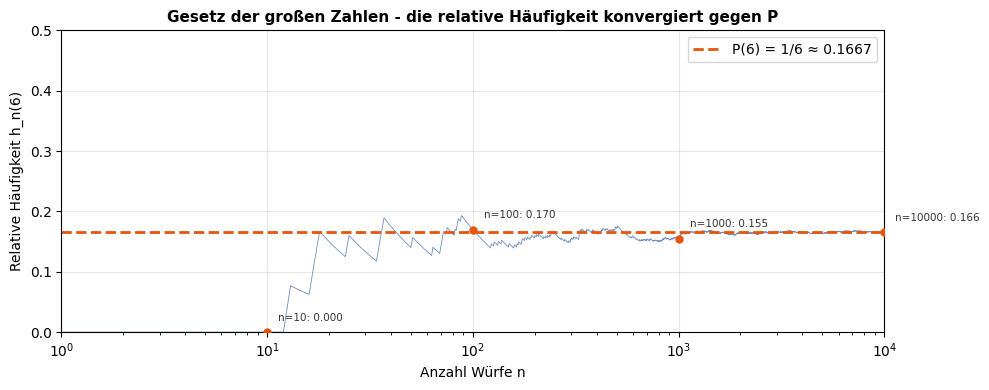

In [6]:
# === Gesetz der großen Zahlen: Relative Häufigkeit → Wahrscheinlichkeit ===
# Simulation: Wie oft fällt eine 6 beim Würfeln?

np.random.seed(42)
n_max = 10_000
wuerfe = np.random.randint(1, 7, size=n_max)

# Kumulative relative Häufigkeit von "6"
ist_sechs = (wuerfe == 6).astype(int)
rel_haeufigkeit = np.cumsum(ist_sechs) / np.arange(1, n_max + 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, n_max + 1), rel_haeufigkeit, color="#4C72B0", linewidth=0.6, alpha=0.8)
ax.axhline(y=1/6, color="#E6550D", linestyle="--", linewidth=2, label=f"P(6) = 1/6 ≈ {1/6:.4f}")
ax.set_xlabel("Anzahl Würfe n")
ax.set_ylabel("Relative Häufigkeit h_n(6)")
ax.set_title("Gesetz der großen Zahlen - die relative Häufigkeit konvergiert gegen P", fontsize=11, fontweight="bold")
ax.set_xscale("log")
ax.set_xlim(1, n_max)
ax.set_ylim(0, 0.5)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Markierungen bei bestimmten n-Werten
for n_mark in [10, 100, 1000, 10000]:
    h = rel_haeufigkeit[n_mark - 1]
    ax.plot(n_mark, h, "o", color="#E6550D", markersize=5, zorder=5)
    ax.annotate(f"n={n_mark}: {h:.3f}", xy=(n_mark, h), fontsize=7.5,
                textcoords="offset points", xytext=(8, 8), color="#333333")

plt.tight_layout()
plt.show()

### 4. Rechenregeln und Sätze

Alle folgenden Regeln lassen sich aus den drei Kolmogorow-Axiomen ableiten. Sie bilden das Handwerkszeug für jede Wahrscheinlichkeitsrechnung.

#### 4.1 Komplementärregel

Die vielleicht nützlichste Regel überhaupt:

$$P(\bar{A}) = 1 - P(A)$$

**Beweis aus den Axiomen:** Da $A$ und $\bar{A}$ disjunkt sind und $A \cup \bar{A} = \Omega$, folgt aus Axiom 3:
$P(\Omega) = P(A) + P(\bar{A})$. Mit Axiom 2 ($P(\Omega) = 1$) ergibt sich sofort $P(\bar{A}) = 1 - P(A)$. $\square$

Diese Regel ist besonders praktisch, wenn das Gegenereignis **einfacher zu berechnen** ist als das Ereignis selbst. Klassisches Beispiel: „Mindestens einmal eine 6 bei 4 Würfen" ist mühsam direkt zu zählen. Aber das Gegenereignis „keine einzige 6" ist einfach:

$$P(\text{mind. eine 6}) = 1 - P(\text{keine 6}) = 1 - \left(\frac{5}{6}\right)^4 \approx 0{,}518$$

#### 4.2 Additionssatz

Für **beliebige** Ereignisse $A$ und $B$ gilt:

$$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

Der Term $-P(A \cap B)$ korrigiert die **Doppelzählung**: Ergebnisse, die in *beiden* Ereignissen liegen, würden sonst zweimal gezählt. Das Venn-Diagramm oben macht das unmittelbar anschaulich.

Für **disjunkte** Ereignisse ($A \cap B = \emptyset$) vereinfacht sich dies zu:

$$P(A \cup B) = P(A) + P(B)$$

Das ist im Grunde direkt Axiom 3 - die Additivität.

**Beispiel:** Aus einem Skatspiel (32 Karten) wird eine Karte gezogen. $A$: „Herz" (8 Karten), $B$: „König" (4 Karten), $A \cap B$: „Herz-König" (1 Karte).

$$P(A \cup B) = \frac{8}{32} + \frac{4}{32} - \frac{1}{32} = \frac{11}{32}$$

#### 4.3 Siebformel für drei Ereignisse

Bei drei Ereignissen ist die Idee dieselbe - Doppelzählungen subtrahieren, Dreifachzählung wieder addieren:

$$P(A \cup B \cup C) = P(A) + P(B) + P(C) - P(A \cap B) - P(A \cap C) - P(B \cap C) + P(A \cap B \cap C)$$

#### 4.4 Weitere Folgerungen aus den Axiomen

Einige weitere nützliche Eigenschaften, die direkt aus den Axiomen folgen:

- **Unmögliches Ereignis:** $P(\emptyset) = 0$
- **Monotonie:** Wenn $A \subseteq B$, dann $P(A) \leq P(B)$
- **Beschränktheit:** $0 \leq P(A) \leq 1$ für alle $A$
- **Subadditivität:** $P(A \cup B) \leq P(A) + P(B)$ (auch Boole'sche Ungleichung)

---

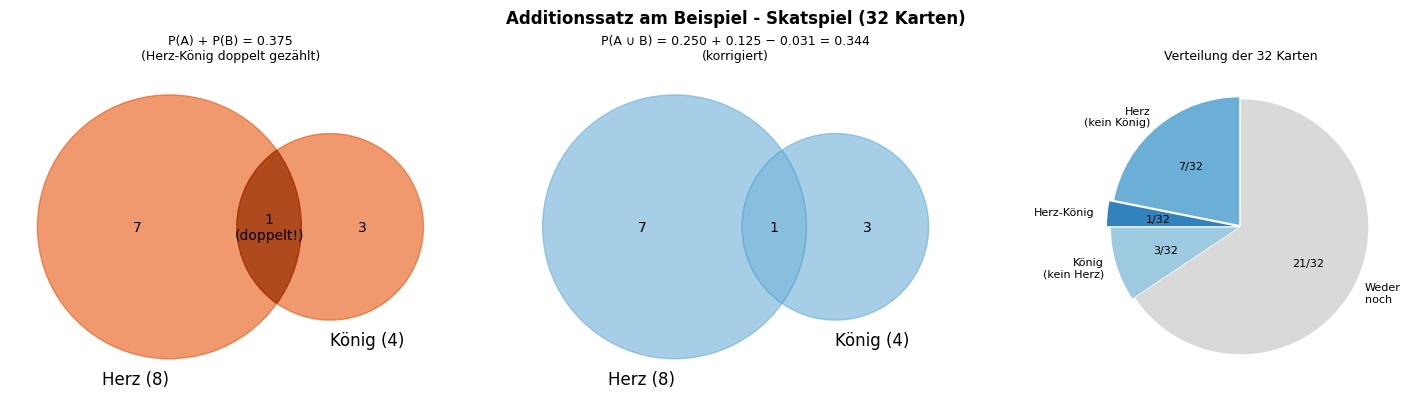

In [ ]:
# === Additionssatz visuell: Skatspiel-Beispiel ===
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Additionssatz am Beispiel - Skatspiel (32 Karten)", fontsize=12, fontweight="bold")

# Konfiguration
P_A = 8/32    # Herz
P_B = 4/32    # König
P_AB = 1/32   # Herz-König
P_AuB = P_A + P_B - P_AB

# 1. P(A) + P(B) - mit Doppelzählung
v1 = venn2(subsets=(7, 3, 1), set_labels=("Herz (8)", "König (4)"), ax=axes[0])
v1.get_patch_by_id("10").set_color("#E6550D")
v1.get_patch_by_id("01").set_color("#E6550D")
v1.get_patch_by_id("11").set_color("#A63603")
v1.get_patch_by_id("10").set_alpha(0.6)
v1.get_patch_by_id("01").set_alpha(0.6)
v1.get_patch_by_id("11").set_alpha(0.9)
v1.get_label_by_id("10").set_text("7")
v1.get_label_by_id("01").set_text("3")
v1.get_label_by_id("11").set_text("1\n(doppelt!)")
axes[0].set_title(f"P(A) + P(B) = {P_A + P_B:.3f}\n(Herz-König doppelt gezählt)", fontsize=9)

# 2. Korrektur: - P(A ∩ B)
v2 = venn2(subsets=(7, 3, 1), set_labels=("Herz (8)", "König (4)"), ax=axes[1])
v2.get_patch_by_id("10").set_color("#6BAED6")
v2.get_patch_by_id("01").set_color("#6BAED6")
v2.get_patch_by_id("11").set_color("#6BAED6")
v2.get_patch_by_id("10").set_alpha(0.6)
v2.get_patch_by_id("01").set_alpha(0.6)
v2.get_patch_by_id("11").set_alpha(0.8)
v2.get_label_by_id("10").set_text("7")
v2.get_label_by_id("01").set_text("3")
v2.get_label_by_id("11").set_text("1")
axes[1].set_title(f"P(A ∪ B) = {P_A:.3f} + {P_B:.3f} − {P_AB:.3f} = {P_AuB:.3f}\n(korrigiert)", fontsize=9)

# 3. Überblick: Wahrscheinlichkeiten als Flächenanteile
labels = ["Herz\n(kein König)", "Herz-König", "König\n(kein Herz)", "Weder\nnoch"]
sizes = [7, 1, 3, 21]
colors = ["#6BAED6", "#3182BD", "#9ECAE1", "#D9D9D9"]
explode = (0.02, 0.05, 0.02, 0)
axes[2].pie(sizes, labels=labels, colors=colors, explode=explode, autopct=lambda p: f"{p*32/100:.0f}/32",
            startangle=90, textprops={"fontsize": 8})
axes[2].set_title("Verteilung der 32 Karten", fontsize=9)

plt.tight_layout()
plt.show()

### 5. Kombinatorik

Um die Laplace-Formel $P(A) = \frac{|A|}{|\Omega|}$ anwenden zu können, müssen wir die Elemente in $A$ und $\Omega$ **abzählen** können. Bei kleinen Mengen geht das durch Aufzählen - aber wie viele Möglichkeiten gibt es, 6 Zahlen aus 45 zu ziehen? Da brauchen wir systematische **Zähltechniken**.

#### 5.1 Produktregel (Grundprinzip des Zählens)

Wenn ein Vorgang aus **aufeinanderfolgenden Stufen** besteht - Stufe 1 hat $n_1$ Möglichkeiten, Stufe 2 hat $n_2$ Möglichkeiten, usw. - dann gibt es insgesamt

$$n_1 \cdot n_2 \cdot \ldots \cdot n_k$$

verschiedene Gesamtmöglichkeiten. Das klingt trivial, ist aber das Fundament aller folgenden Formeln.

**Beispiel:** Ein Menü besteht aus Vorspeise (3 Optionen), Hauptgang (5 Optionen) und Dessert (2 Optionen). Die Gesamtanzahl verschiedener Menüs ist $3 \cdot 5 \cdot 2 = 30$.

#### 5.2 Permutationen

Eine **Permutation** ist eine Anordnung aller $n$ Elemente in einer bestimmten Reihenfolge. Für die erste Position gibt es $n$ Möglichkeiten, für die zweite $n-1$, usw.:

$$n! = n \cdot (n-1) \cdot (n-2) \cdots 2 \cdot 1$$

Per Konvention gilt $0! = 1$.

**Beispiel:** 5 Personen stellen sich in einer Reihe auf → $5! = 120$ verschiedene Anordnungen.

Wenn unter den $n$ Elementen **Wiederholungen** vorkommen (z.B. identische Buchstaben), so teilt man durch die Fakultäten der Wiederholungsanzahlen:

$$\frac{n!}{k_1! \cdot k_2! \cdots k_r!}$$

**Beispiel:** Das Wort MISSISSIPPI hat $n = 11$ Buchstaben mit M×1, I×4, S×4, P×2. Die Anzahl verschiedener Anordnungen ist $\frac{11!}{1! \cdot 4! \cdot 4! \cdot 2!} = 34\,650$.

#### 5.3 Variation (k aus n, mit Reihenfolge)

Wenn wir nicht alle $n$ Elemente anordnen, sondern nur $k$ davon **auswählen und anordnen** (ohne Zurücklegen):

$$V(n, k) = \frac{n!}{(n-k)!} = n \cdot (n-1) \cdots (n-k+1)$$

**Beispiel:** Podestplätze (Gold, Silber, Bronze) bei 10 Athleten: $\frac{10!}{7!} = 10 \cdot 9 \cdot 8 = 720$.

#### 5.4 Kombination (k aus n, ohne Reihenfolge)

Oft interessiert uns nur **welche** Elemente gewählt werden, nicht in welcher Reihenfolge. Dann dividieren wir die Variation durch die $k!$ möglichen Anordnungen der ausgewählten Elemente:

$$\binom{n}{k} = \frac{n!}{k! \cdot (n-k)!}$$

Dies ist der **Binomialkoeffizient**, gelesen als „$n$ über $k$". Er hat einige wichtige Eigenschaften:

- **Symmetrie:** $\binom{n}{k} = \binom{n}{n-k}$ - aus 10 Elementen 3 auszuwählen ist dasselbe wie 7 *nicht* auszuwählen.
- **Randfälle:** $\binom{n}{0} = \binom{n}{n} = 1$ - es gibt genau eine Möglichkeit, nichts (oder alles) zu wählen.
- **Rekursion:** $\binom{n}{k} = \binom{n-1}{k-1} + \binom{n-1}{k}$ - das ergibt das **Pascalsche Dreieck**.

**Beispiel (Lotto „6 aus 45"):** Die Anzahl möglicher Tipps ist $\binom{45}{6} = \frac{45!}{6! \cdot 39!} = 8\,145\,060$. Die Wahrscheinlichkeit eines Sechsers beträgt also $P = \frac{1}{8\,145\,060} \approx 1{,}23 \cdot 10^{-7}$.

#### 5.5 Entscheidungshilfe: Welche Formel?

Die Wahl der richtigen Formel hängt von zwei Fragen ab:

1. **Ist die Reihenfolge relevant?** (Podestplätze vs. Lottozahlen)
2. **Wird mit oder ohne Zurücklegen gezogen?** (Würfeln vs. Kartenziehen)

| | **Ohne Zurücklegen** | **Mit Zurücklegen** |
|---|---|---|
| **Mit Reihenfolge** | Variation: $\frac{n!}{(n-k)!}$ | $n^k$ |
| **Ohne Reihenfolge** | Kombination: $\binom{n}{k}$ | $\binom{n+k-1}{k}$ |

> **Tipp für Aufgaben:** Lies die Aufgabe und frage dich: *„Zähle ich geordnete Tupel oder ungeordnete Teilmengen?"* Das beantwortet die Reihenfolgen-Frage. Und: *„Kann dasselbe Element mehrfach vorkommen?"* beantwortet die Zurücklegen-Frage.

---

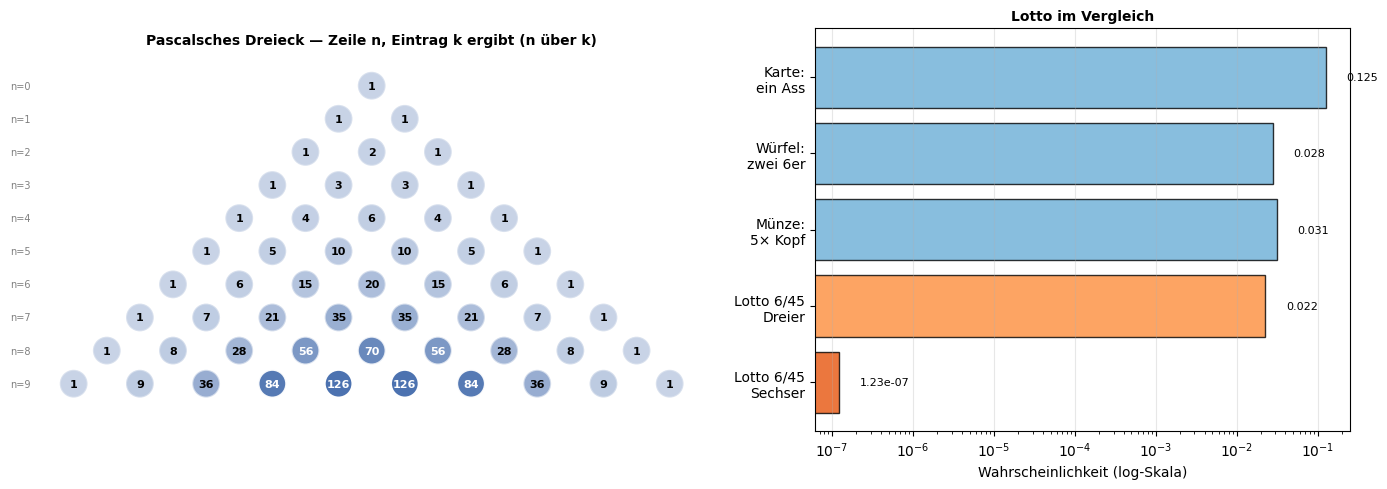

In [9]:
# === Pascalsches Dreieck + Lotto-Beispiel ===

# --- Pascalsches Dreieck als Heatmap ---
n_rows = 10
triangle = np.zeros((n_rows, 2 * n_rows - 1))

for n in range(n_rows):
    for k in range(n + 1):
        col = (n_rows - 1 - n) + 2 * k  # zentriert
        triangle[n, col] = math.comb(n, k)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})

# Pascalsches Dreieck
ax1 = axes[0]
for n in range(n_rows):
    for k in range(n + 1):
        col = (n_rows - 1 - n) + 2 * k
        val = math.comb(n, k)
        circle = plt.Circle((col, -n), 0.42, color="#4C72B0",
                            alpha=min(0.3 + val / 130, 1.0), ec="white", linewidth=1.5)
        ax1.add_patch(circle)
        ax1.text(col, -n, str(val), ha="center", va="center",
                fontsize=8, fontweight="bold", color="white" if val > 50 else "black")

ax1.set_xlim(-1.5, 2 * n_rows - 0.5)
ax1.set_ylim(-n_rows + 0.3, 1)
ax1.set_aspect("equal")
ax1.set_title("Pascalsches Dreieck — Zeile n, Eintrag k ergibt (n über k)", fontsize=10, fontweight="bold")
ax1.axis("off")

# Zeilen-Labels
for n in range(n_rows):
    ax1.text(-1.3, -n, f"n={n}", ha="right", va="center", fontsize=7, color="gray")

# --- Lotto 6 aus 45: Vergleich mit Alltagswahrscheinlichkeiten ---
ax2 = axes[1]
lotto_p = 1 / math.comb(45, 6)
vergleiche = {
    "Lotto 6/45\nSechser": lotto_p,
    "Lotto 6/45\nDreier": math.comb(6,3) * math.comb(39,3) / math.comb(45,6),
    "Münze:\n5× Kopf": (1/2)**5,
    "Würfel:\nzwei 6er": (1/6)**2,
    "Karte:\nein Ass": 4/32,
}

namen = list(vergleiche.keys())
werte = list(vergleiche.values())
farben = ["#E6550D", "#FD8D3C", "#6BAED6", "#6BAED6", "#6BAED6"]

bars = ax2.barh(namen, werte, color=farben, edgecolor="black", alpha=0.8)
ax2.set_xscale("log")
ax2.set_xlabel("Wahrscheinlichkeit (log-Skala)")
ax2.set_title("Lotto im Vergleich", fontsize=10, fontweight="bold")

for bar, w in zip(bars, werte):
    ax2.text(w * 1.8, bar.get_y() + bar.get_height()/2,
             f"{w:.2e}" if w < 0.001 else f"{w:.3f}",
             va="center", fontsize=8)

ax2.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

### 6. Bedingte Wahrscheinlichkeit und Unabhängigkeit

Bisher haben wir Wahrscheinlichkeiten „im Vakuum" berechnet - ohne Vorwissen. In der Realität kennen wir aber oft **Zusatzinformationen**: Der Patient hat Fieber, die erste gezogene Karte war ein Ass, es regnet. Solches Vorwissen **verändert** die Wahrscheinlichkeiten - und genau das formalisiert die bedingte Wahrscheinlichkeit.

#### 6.1 Bedingte Wahrscheinlichkeit

> **Definition:** Die **bedingte Wahrscheinlichkeit** von $A$ *unter der Bedingung* $B$ (gegeben $B$ ist eingetreten, $P(B) > 0$) ist:
>
> $$P(A \mid B) = \frac{P(A \cap B)}{P(B)}$$

Die Intuition: Wenn wir wissen, dass $B$ eingetreten ist, reduziert sich unser „Universum" von $\Omega$ auf $B$. Innerhalb dieses eingeschränkten Universums fragen wir: Wie groß ist der Anteil von $A$?

**Beispiel:** Zwei faire Würfel werden geworfen. Sei $A$: „Augensumme $\geq 9$" und $B$: „der erste Würfel zeigt 5".

- $\Omega = \{(i,j) : i,j \in \{1,\ldots,6\}\}$ mit $|\Omega| = 36$
- $B = \{(5,1), (5,2), \ldots, (5,6)\}$ mit $|B| = 6$
- $A \cap B = \{(5,4), (5,5), (5,6)\}$ mit $|A \cap B| = 3$

$$P(A \mid B) = \frac{3/36}{6/36} = \frac{3}{6} = \frac{1}{2}$$

Ohne die Bedingung wäre $P(A) = \frac{10}{36} \approx 0{,}278$. Das Wissen, dass der erste Würfel eine 5 zeigt, hat die Wahrscheinlichkeit einer hohen Summe fast **verdoppelt** - intuitiv nachvollziehbar.

#### 6.2 Multiplikationssatz

Durch Umstellen der Definition erhalten wir den **Multiplikationssatz**:

$$P(A \cap B) = P(A \mid B) \cdot P(B) = P(B \mid A) \cdot P(A)$$

Dieser Satz ist die Grundlage für das Rechnen mit **Baumdiagrammen**, weil er die Wahrscheinlichkeit einer Schnittmenge als Produkt entlang eines „Pfades" ausdrückt.

#### 6.3 Unabhängigkeit

In manchen Situationen ändert das Wissen über $B$ die Wahrscheinlichkeit von $A$ **nicht**. Dann heißen $A$ und $B$ **stochastisch unabhängig**.

> **Definition:** Zwei Ereignisse $A$ und $B$ heißen **unabhängig**, wenn gilt:
>
> $$P(A \cap B) = P(A) \cdot P(B)$$
>
> Äquivalent (falls $P(B) > 0$): $P(A \mid B) = P(A)$

**Beispiele:**
- Zwei aufeinanderfolgende Münzwürfe sind unabhängig - das Ergebnis des ersten beeinflusst den zweiten nicht.
- Zweimaliges Ziehen *ohne Zurücklegen* ist **nicht** unabhängig - nach dem Ziehen einer Karte hat sich die Zusammensetzung des Stapels geändert.

> **Warnung: Unabhängig $\neq$ Disjunkt!** Diese Verwechslung ist häufig und gefährlich. Disjunkte Ereignisse ($A \cap B = \emptyset$) sind im Gegenteil fast immer **stark abhängig**: Wenn $A$ eintritt, kann $B$ *nicht* eintreten, also $P(B \mid A) = 0 \neq P(B)$.

#### 6.4 Baumdiagramme und Pfadregeln

Bei **mehrstufigen Zufallsexperimenten** (z.B. mehrfaches Ziehen) sind Baumdiagramme das zentrale Werkzeug. An jeder Verzweigung steht die bedingte Wahrscheinlichkeit der nächsten Stufe.

Es gelten zwei Regeln:
- **Pfadmultiplikationsregel:** Die Wahrscheinlichkeit eines vollständigen Pfades ist das **Produkt** aller Wahrscheinlichkeiten entlang des Pfades (das ist der Multiplikationssatz in Aktion).
- **Pfadadditionsregel:** Die Wahrscheinlichkeit eines Ereignisses ist die **Summe** der Wahrscheinlichkeiten aller Pfade, die zu diesem Ereignis führen.

**Beispiel:** Eine Urne enthält 3 rote und 2 blaue Kugeln. Es wird zweimal *ohne Zurücklegen* gezogen. Wie groß ist die Wahrscheinlichkeit, genau eine rote und eine blaue Kugel zu ziehen?

Pfad „rot, dann blau": $\frac{3}{5} \cdot \frac{2}{4} = \frac{6}{20}$

Pfad „blau, dann rot": $\frac{2}{5} \cdot \frac{3}{4} = \frac{6}{20}$

$$P(\text{genau eine rote}) = \frac{6}{20} + \frac{6}{20} = \frac{12}{20} = \frac{3}{5}$$

---

In [ ]:
# === Baumdiagramm: Urne mit 3 roten und 2 blauen Kugeln, Ziehen ohne Zurücklegen ===

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(-0.5, 10)
ax.set_ylim(-0.5, 6.5)
ax.axis("off")
ax.set_title("Baumdiagramm - Urne: 3R + 2B, Ziehen ohne Zurücklegen", fontsize=12, fontweight="bold")

# Konfiguration: Positionen
root = (1, 3.25)
l1_top = (4, 5.2)     # Rot (1. Zug)
l1_bot = (4, 1.3)     # Blau (1. Zug)
l2_rr = (7.5, 6.0)    # R→R
l2_rb = (7.5, 4.4)    # R→B
l2_br = (7.5, 2.1)    # B→R
l2_bb = (7.5, 0.5)    # B→B

rot = "#E6550D"
blau = "#3182BD"
grau = "#666666"

def draw_branch(ax, start, end, label, color, prob):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-", color=color, lw=2))
    mid_x = (start[0] + end[0]) / 2
    mid_y = (start[1] + end[1]) / 2
    offset = (0.15, 0.25) if end[1] > start[1] else (0.15, -0.35)
    ax.text(mid_x + offset[0], mid_y + offset[1], prob,
            fontsize=10, color=grau, fontstyle="italic", ha="center")

# Stufe 1
draw_branch(ax, root, l1_top, "R", rot, "3/5")
draw_branch(ax, root, l1_bot, "B", blau, "2/5")

# Stufe 2 von Rot
draw_branch(ax, l1_top, l2_rr, "R", rot, "2/4")
draw_branch(ax, l1_top, l2_rb, "B", blau, "2/4")

# Stufe 2 von Blau
draw_branch(ax, l1_bot, l2_br, "R", rot, "3/4")
draw_branch(ax, l1_bot, l2_bb, "B", blau, "1/4")

# Knoten-Labels
for pos, label, col in [(root, "Start", "black"),
                         (l1_top, "R", rot), (l1_bot, "B", blau),
                         (l2_rr, "R", rot), (l2_rb, "B", blau),
                         (l2_br, "R", rot), (l2_bb, "B", blau)]:
    circle = plt.Circle(pos, 0.3, color=col if label != "Start" else "#D9D9D9",
                        alpha=0.3, ec=col, linewidth=2, zorder=5)
    ax.add_patch(circle)
    ax.text(pos[0], pos[1], label, ha="center", va="center",
            fontsize=10, fontweight="bold", color=col, zorder=6)

# Pfad-Ergebnisse rechts
ergebnisse = [
    (l2_rr, "RR", f"3/5 · 2/4 = 6/20", rot),
    (l2_rb, "RB", f"3/5 · 2/4 = 6/20", blau),
    (l2_br, "BR", f"2/5 · 3/4 = 6/20", rot),
    (l2_bb, "BB", f"2/5 · 1/4 = 2/20", blau),
]

for pos, name, rechnung, col in ergebnisse:
    ax.text(pos[0] + 0.5, pos[1] + 0.15, name, fontsize=10, fontweight="bold", color=col)
    ax.text(pos[0] + 0.5, pos[1] - 0.25, rechnung, fontsize=8, color=grau)

# Hervorhebung: genau 1R + 1B
ax.annotate("← genau 1R + 1B: 6/20 + 6/20 = 12/20 = 3/5",
            xy=(8.3, 3.25), fontsize=10, fontweight="bold", color="#333333",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFFFCC", edgecolor="#999999"))

plt.tight_layout()
plt.show()

### 7. Totale Wahrscheinlichkeit und Satz von Bayes

Die bedingte Wahrscheinlichkeit erlaubt uns, Wahrscheinlichkeiten „vorwärts" zu berechnen - von Ursachen zu Wirkungen: Gegeben eine Krankheit, wie wahrscheinlich ist ein positiver Test? Doch oft ist die umgekehrte Frage relevanter: *Gegeben ein positiver Test, wie wahrscheinlich ist die Krankheit?* Genau das leistet der Satz von Bayes.

#### 7.1 Zerlegung des Grundraums

Bevor wir Bayes formulieren können, brauchen wir das Konzept einer **Zerlegung**. Die Ereignisse $B_1, B_2, \ldots, B_k$ bilden eine Zerlegung von $\Omega$, wenn sie:
- **paarweise disjunkt** sind: $B_i \cap B_j = \emptyset$ für $i \neq j$
- $\Omega$ **vollständig überdecken**: $B_1 \cup B_2 \cup \cdots \cup B_k = \Omega$

Ein typisches Beispiel: $B_1 =$ „krank" und $B_2 =$ „gesund" zerlegen die Gesamtpopulation in zwei disjunkte, vollständige Gruppen.

#### 7.2 Satz der totalen Wahrscheinlichkeit

Wenn wir die Wahrscheinlichkeit von $A$ nicht direkt kennen, aber wissen, wie wahrscheinlich $A$ **innerhalb jeder Gruppe** $B_i$ ist, können wir $P(A)$ als gewichtete Summe berechnen:

> **Satz (totale Wahrscheinlichkeit):** Sei $B_1, \ldots, B_k$ eine Zerlegung von $\Omega$ mit $P(B_i) > 0$. Dann gilt:
>
> $$P(A) = \sum_{i=1}^{k} P(A \mid B_i) \cdot P(B_i)$$

Im Baumdiagramm entspricht das der **Pfadadditionsregel für alle Pfade, die zu $A$ führen** - über jede Abzweigung $B_i$ hinweg.

#### 7.3 Satz von Bayes

Nun können wir die „Umkehrung" formulieren - von der Wirkung zurück auf die Ursache:

> **Satz von Bayes:** Unter denselben Voraussetzungen gilt:
>
> $$P(B_j \mid A) = \frac{P(A \mid B_j) \cdot P(B_j)}{\sum_{i=1}^{k} P(A \mid B_i) \cdot P(B_i)} = \frac{P(A \mid B_j) \cdot P(B_j)}{P(A)}$$

Im Nenner steht gerade die totale Wahrscheinlichkeit $P(A)$. Der Satz von Bayes ist also eine direkte Kombination aus der Definition der bedingten Wahrscheinlichkeit und dem Satz der totalen Wahrscheinlichkeit.

**Die Begriffe der Bayes'schen Analyse:**
- $P(B_j)$ - die **Apriori-Wahrscheinlichkeit** (*prior*): Was wir über $B_j$ wissen, *bevor* wir $A$ beobachten.
- $P(A \mid B_j)$ - die **Likelihood**: Wie wahrscheinlich ist die Beobachtung $A$, wenn $B_j$ wahr ist?
- $P(B_j \mid A)$ - die **Aposteriori-Wahrscheinlichkeit** (*posterior*): Was wir über $B_j$ wissen, *nachdem* wir $A$ beobachtet haben.
- $P(A)$ - die **Evidenz**: Normierungskonstante, damit sich die Aposteriori-Wahrscheinlichkeiten zu 1 aufaddieren.

#### 7.4 Anwendung: Medizinischer Test

Ein medizinischer Test für eine Krankheit hat folgende Kennzahlen:
- **Prävalenz** (Vorab-Wahrscheinlichkeit): $P(\text{krank}) = 0{,}001$ - einer von 1000 Menschen ist krank.
- **Sensitivität**: $P(\text{positiv} \mid \text{krank}) = 0{,}99$ - der Test erkennt 99% der Kranken.
- **Spezifität**: $P(\text{negativ} \mid \text{gesund}) = 0{,}95$ - der Test identifiziert 95% der Gesunden korrekt.

**Frage:** Eine Person wird positiv getestet. Wie wahrscheinlich ist sie tatsächlich krank?

$$P(\text{krank} \mid \text{positiv}) = \frac{P(\text{pos} \mid \text{krank}) \cdot P(\text{krank})}{P(\text{pos} \mid \text{krank}) \cdot P(\text{krank}) + P(\text{pos} \mid \text{gesund}) \cdot P(\text{gesund})}$$

$$= \frac{0{,}99 \cdot 0{,}001}{0{,}99 \cdot 0{,}001 + 0{,}05 \cdot 0{,}999} = \frac{0{,}00099}{0{,}00099 + 0{,}04995} \approx 0{,}0194$$

**Nur knapp 2%!** Obwohl der Test eine Sensitivität von 99% hat, ist die Person mit über 98% Wahrscheinlichkeit *gesund*. Der Grund: Die Krankheit ist so selten, dass die wenigen falsch-positiven Ergebnisse unter den vielen Gesunden die wenigen wahr-positiven Ergebnisse **zahlenmäßig erdrücken**. Das ist das berühmte **Base-Rate-Paradox** - und einer der Gründe, warum der Satz von Bayes so fundamental ist.

---

In [ ]:
# === Bayes: Medizinischer Test - Einfluss der Prävalenz ===

# Konfiguration
sensitivitaet = 0.99
spezifizitaet = 0.95
praevalenzen = np.linspace(0.0001, 0.15, 300)

# Bayes-Berechnung für verschiedene Prävalenzen
posterior = (sensitivitaet * praevalenzen) / (
    sensitivitaet * praevalenzen + (1 - spezifizitaet) * (1 - praevalenzen)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Links: Posterior vs. Prävalenz ---
ax1 = axes[0]
ax1.plot(praevalenzen * 100, posterior * 100, color="#E6550D", linewidth=2.5)
ax1.axhline(y=50, color="gray", linestyle=":", alpha=0.5)

# Markierungen bei bestimmten Prävalenzen
for pv, label in [(0.001, "0,1%"), (0.01, "1%"), (0.05, "5%"), (0.10, "10%")]:
    post = (sensitivitaet * pv) / (sensitivitaet * pv + (1 - spezifizitaet) * (1 - pv))
    ax1.plot(pv * 100, post * 100, "o", color="#3182BD", markersize=7, zorder=5)
    ax1.annotate(f"Präv={label}\n→ {post*100:.1f}%",
                xy=(pv * 100, post * 100), fontsize=8,
                textcoords="offset points", xytext=(12, -5), color="#333333",
                arrowprops=dict(arrowstyle="->", color="gray", lw=0.8))

ax1.set_xlabel("Prävalenz (%)")
ax1.set_ylabel("P(krank | positiv) in %")
ax1.set_title("Wie die Prävalenz den Vorhersagewert bestimmt", fontsize=10, fontweight="bold")
ax1.set_xlim(0, 15)
ax1.set_ylim(0, 100)
ax1.grid(True, alpha=0.3)

# --- Rechts: Natürliche Häufigkeiten (Baumdiagramm als Mosaik) ---
ax2 = axes[1]
N = 10_000
praevalenz = 0.001
krank = int(N * praevalenz)
gesund = N - krank
richtig_pos = int(krank * sensitivitaet)
falsch_neg = krank - richtig_pos
falsch_pos = int(gesund * (1 - spezifizitaet))
richtig_neg = gesund - falsch_pos

kategorien = ["Richtig\npositiv", "Falsch\npositiv", "Falsch\nnegativ", "Richtig\nnegativ"]
werte = [richtig_pos, falsch_pos, falsch_neg, richtig_neg]
farben = ["#E6550D", "#FDAE6B", "#9ECAE1", "#3182BD"]

bars = ax2.bar(kategorien, werte, color=farben, edgecolor="black", alpha=0.85)
ax2.set_ylabel(f"Anzahl Personen (von {N:,})")
ax2.set_title(f"Natürliche Häufigkeiten bei Prävalenz = {praevalenz*100:.1f}%", fontsize=10, fontweight="bold")

for bar, w in zip(bars, werte):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
             f"{w:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax2.annotate(f"P(krank|pos) = {richtig_pos}/{richtig_pos+falsch_pos}"
             f" ≈ {richtig_pos/(richtig_pos+falsch_pos):.1%}",
             xy=(0.5, max(werte) * 0.85), fontsize=11, fontweight="bold", color="#E6550D",
             xycoords=("axes fraction", "data"),
             bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFFFCC", edgecolor="#999999"))

ax2.set_yscale("log")
ax2.set_ylim(0.5, N * 1.5)
ax2.grid(True, alpha=0.3, axis="y")

fig.suptitle("Satz von Bayes - Das Base-Rate-Paradox", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---

## Verständnis-Check

*Löse die folgenden Aufgaben auf Papier.*

**Aufgabe 1:** In einer Urne liegen 4 rote, 3 blaue und 2 grüne Kugeln. Es wird zweimal **ohne** Zurücklegen gezogen.

a) Wie groß ist $P(\text{beide rot})$?

b) Wie groß ist $P(\text{mindestens eine blaue})$?

**Aufgabe 2:** Ein Test erkennt eine Krankheit mit $P(\text{positiv} \mid \text{krank}) = 0{,}95$. Die Falsch-Positiv-Rate ist $P(\text{positiv} \mid \text{gesund}) = 0{,}03$. Die Krankheit betrifft 1 % der Bevölkerung.

Berechne $P(\text{krank} \mid \text{positiv})$ mit dem Satz von Bayes.

**Aufgabe 3:** Aus einer Gruppe von 10 Personen wird ein 3er-Komitee gewählt. Wie viele Möglichkeiten gibt es? Wäre die Antwort anders, wenn die Reihenfolge eine Rolle spielte (z. B. Vorsitz, Stellvertretung, Schriftführung)?

**Aufgabe 4:** Zwei faire Würfel werden geworfen. Ereignisse: $A$: „Augensumme $= 7$", $B$: „mindestens ein Würfel zeigt 3".

a) Berechne $P(A)$, $P(B)$ und $P(A \cap B)$.

b) Sind $A$ und $B$ unabhängig?

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

a) $P(\text{beide rot}) = \dfrac{4}{9} \cdot \dfrac{3}{8} = \dfrac{12}{72} = \dfrac{1}{6} \approx 0{,}167$

b) Gegenereignis: *keine* blaue Kugel.

$P(\text{keine blaue}) = \dfrac{6}{9} \cdot \dfrac{5}{8} = \dfrac{30}{72} = \dfrac{5}{12}$

$P(\text{mind. eine blaue}) = 1 - \dfrac{5}{12} = \dfrac{7}{12} \approx 0{,}583$
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

Gegeben: $P(+|K) = 0{,}95$, $P(+|G) = 0{,}03$, $P(K) = 0{,}01$, $P(G) = 0{,}99$.

Totale Wahrscheinlichkeit: $P(+) = P(+|K) \cdot P(K) + P(+|G) \cdot P(G) = 0{,}95 \cdot 0{,}01 + 0{,}03 \cdot 0{,}99 = 0{,}0095 + 0{,}0297 = 0{,}0392$

Bayes: $P(K|+) = \dfrac{P(+|K) \cdot P(K)}{P(+)} = \dfrac{0{,}0095}{0{,}0392} \approx 0{,}242$

Nur ca. 24 % der positiv Getesteten sind tatsächlich krank — trotz 95 % Sensitivität! Der Grund: die Krankheit ist selten (niedrige Basisrate).
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

Ohne Reihenfolge (Kombination): $\binom{10}{3} = \dfrac{10!}{3! \cdot 7!} = \dfrac{10 \cdot 9 \cdot 8}{3 \cdot 2 \cdot 1} = 120$

Mit Reihenfolge (Variation): $\dfrac{10!}{7!} = 10 \cdot 9 \cdot 8 = 720$

Ja, mit Reihenfolge gibt es 6-mal so viele Möglichkeiten ($3! = 6$).
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

$|\Omega| = 36$.

a) $A = \{(1,6),(2,5),(3,4),(4,3),(5,2),(6,1)\}$ → $P(A) = \frac{6}{36} = \frac{1}{6}$

$B$: mindestens ein 3er → $|B| = 11$ (6+6−1) → $P(B) = \frac{11}{36}$

$A \cap B = \{(3,4),(4,3)\}$ → $P(A \cap B) = \frac{2}{36} = \frac{1}{18}$

b) Unabhängig, falls $P(A \cap B) = P(A) \cdot P(B)$:

$P(A) \cdot P(B) = \frac{1}{6} \cdot \frac{11}{36} = \frac{11}{216} \approx 0{,}0509$

$P(A \cap B) = \frac{1}{18} \approx 0{,}0556$

$\frac{11}{216} \neq \frac{1}{18}$ → $A$ und $B$ sind **nicht unabhängig**.
</details>

## Zusammenfassung

| Konzept | Formel | Bemerkung |
|---------|--------|-----------|
| **Laplace** | $P(A) = \frac{|A|}{|\Omega|}$ | Nur bei Gleichwahrscheinlichkeit |
| **Komplementärregel** | $P(\bar{A}) = 1 - P(A)$ | Nützlich für „mindestens"-Aufgaben |
| **Additionssatz** | $P(A \cup B) = P(A) + P(B) - P(A \cap B)$ | Allgemein gültig |
| **Bedingte W'keit** | $P(A \mid B) = \frac{P(A \cap B)}{P(B)}$ | $B$ schränkt $\Omega$ ein |
| **Multiplikationssatz** | $P(A \cap B) = P(A \mid B) \cdot P(B)$ | Grundlage der Pfadmultiplikation |
| **Unabhängigkeit** | $P(A \cap B) = P(A) \cdot P(B)$ | $B$ ändert nichts an $P(A)$ |
| **Totale W'keit** | $P(A) = \sum P(A \mid B_i) \cdot P(B_i)$ | $B_i$ bilden Zerlegung von $\Omega$ |
| **Bayes** | $P(B_j \mid A) = \frac{P(A \mid B_j) \cdot P(B_j)}{P(A)}$ | Umkehrung der Bedingung |
| **Permutation** | $n!$ | Anordnung aller $n$ Elemente |
| **Kombination** | $\binom{n}{k} = \frac{n!}{k!(n-k)!}$ | $k$ aus $n$ ohne Reihenfolge |
| **Variation** | $\frac{n!}{(n-k)!}$ | $k$ aus $n$ mit Reihenfolge |

> **Nächster Schritt:** Was passiert, wenn wir einem Zufallsexperiment eine *Zahl* zuordnen? → 04_Verteilungen

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Zufallsexperiment | Random experiment |
| Ergebnismenge | Sample space |
| Ereignis | Event |
| Wahrscheinlichkeit | Probability |
| Laplace-Experiment | Equally likely outcomes experiment |
| Relative Häufigkeit | Relative frequency |
| Komplementärereignis | Complement |
| Bedingte Wahrscheinlichkeit | Conditional probability |
| Unabhängigkeit | Independence |
| Additionssatz | Addition rule |
| Multiplikationssatz | Multiplication rule |
| Satz von Bayes | Bayes' theorem |
| Baumdiagramm | Tree diagram |
| Pfadregel | Path rule |
| Permutation | Permutation |
| Kombination | Combination |
| Variation | Variation / Arrangement |
| Binomialkoeffizient | Binomial coefficient |